スペクトルデータにpeak|dipがある、無いenergy領域が存在するということは、
そのenergy領域の分散が大きい説明変数があるということです。
例えばPCAで同じpeak|dipがあるスペクトルは同じ説明変数の領域に集まり特徴抽出することができるはずです。
同様に、あるピークがあるDOSと同じピークがあるDOSとは距離が近く、異なるピークがあるDOSをとは距離が遠くなるmetricがあれば距離行列から特徴抽出することができるはずです。
また、
peakのenergy領域が全て同じわけでは無く、ピーク高さやピーク位置が少しずれることも多く、ある幅のenergy windowでsmearingを行うことで、良い特徴抽出を行ったことになる可能性もあります。

その後、クラスタリングにより、何かのmetricで距離が近いデータインスタンスをクラスター分割します。

これらを行ってみます。

以下では、
1. DR_TYPEで指定した次元圧縮を行う。
2. optional: SECOND_PREPROCESSで定義した次元圧縮を更に行う。
3. クラスタリング

を行っています。前処理をどう行うかでクラスタリング結果は大きく異なります。

ただし、表示用時には二次元に次元圧縮しています。

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.core.periodic_table import Element
import numpy as np
import os
import json

In [2]:
# 第一段階
DR_TYPE =  None #  None |"smearing"|"pca"|"mds"|"tsne"
N_SMEARD_DOS = 50 # 2,3,5,10,20,30,40,50  # DR_TYPEによる次元圧縮後の次元を定義する。
_SMEAR_ALPHA = int(50*((N_SMEARD_DOS/5)**2)) # DF_TYPE=="smearing"の時に、SMEARINGのgaussian幅がmesh幅になるように調整している。

# 第二段階
SECOND_PREPROCESS = False # apply DSP_DR_TYPE after applying DF_TYPE dimensionality reduction.
DSP_DR_TYPE = "tsne" # pca|tsne|mds

FIGDIR="image_executed"
os.makedirs(FIGDIR, exist_ok=True)

In [3]:
def get_data():
    filename = "../data/dos/hea4_dos.csv"
    df = pd.read_csv(filename, index_col=None)
    meta_names = ['Z1', 'Z2', 'Z3', 'Z4',
    'elm1', 'elm2', 'elm3', 'elm4', 'elements',  ]
    descriptor_names = []
    for i in range(100):
        descriptor_names.append("log10_dos{}".format(i+1))
    target_name = 'semicore'

    descriptor_names = descriptor_names[0:100]
    return df, descriptor_names, meta_names, target_name

g_df, g_logdos_names, g_meta_names, g_target_name = get_data()
g_descriptor_names = g_logdos_names
g_df

,Z1,Z2,Z3,Z4,log10_dos1,log10_dos2,log10_dos3,log10_dos4,log10_dos5,log10_dos6,...,log10_dos97,log10_dos98,log10_dos99,log10_dos100,elm1,elm2,elm3,elm4,elements,semicore
0,23,25,50,78,-3.113509,-3.045757,-3.000000,-2.974694,-2.958607,-2.954677,...,0.009026,0.044775,0.076284,0.104473,V,Mn,Sn,Pt,",V,Mn,Sn,Pt,",Sn
1,25,26,48,50,-3.040959,-2.974694,-2.935542,-2.913640,-2.906578,-2.906578,...,0.105462,0.195637,0.323516,0.569436,Mn,Fe,Cd,Sn,",Mn,Fe,Cd,Sn,",Sn
2,22,25,28,50,-2.669586,-2.673664,-2.675718,-2.677781,-2.681937,-2.690370,...,-0.064045,-0.022167,0.013562,0.044724,Ti,Mn,Ni,Sn,",Ti,Mn,Ni,Sn,",Sn
3,13,28,50,79,-3.130768,-3.055517,-3.000000,-2.966576,-2.950782,-2.943095,...,0.084891,0.118840,0.149053,0.176386,Al,Ni,Sn,Au,",Al,Ni,Sn,Au,",Sn
4,25,29,44,50,-3.154902,-3.045757,-2.974694,-2.928118,-2.896196,-2.882729,...,0.007411,0.037167,0.063836,0.087955,Mn,Cu,Ru,Sn,",Mn,Cu,Ru,Sn,",Sn
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,24,42,77,79,-3.221849,-3.251812,-3.283997,-3.301030,-3.337242,-3.356547,...,-2.769551,-2.725842,-2.677781,-2.612610,Cr,Mo,Ir,Au,",Cr,Mo,Ir,Au,",Mo
596,25,42,78,79,-3.214670,-3.244125,-3.267606,-3.283997,-3.309804,-3.327902,...,-2.769551,-2.730487,-2.686133,-2.632644,Mn,Mo,Pt,Au,",Mn,Mo,Pt,Au,",Mo
597,29,30,42,77,-3.301030,-3.420216,-3.552842,-3.744727,-3.920819,-4.221849,...,-2.661544,-2.616185,-2.571865,-2.519993,Cu,Zn,Mo,Ir,",Cu,Zn,Mo,Ir,",Mo
598,22,24,42,43,-2.489455,-2.559091,-2.619789,-2.673664,-2.721246,-2.764472,...,-3.075721,-3.065502,-3.045757,-3.026872,Ti,Cr,Mo,Tc,",Ti,Cr,Mo,Tc,",Mo


In [4]:
def plot_x(df, descriptor_names, elm=None, xlabel="energy", ylabel="log10(DOS)", alpha=0.01):
    """plot X

    Args:
        df (pd.DataFrame): data
        descriptor_names ([str]]): a list of explanatory variables.
        elm (str, optional): element symbol to show in a plot. Defaults to None.
        xlabel (str, optional): name of x label. Defaults to "energy".
        ylabel (str, optional): name of y label. Defaults to "log10(DOS)".
        alpha (float, optional): alpha value of plot. Defaults to 0.01.
    """
    if elm is not None:
        dfq = df[df["elements"].str.contains(elm)]
        if dfq.shape[0]==0:
            print("elm={} 0".format(elm))
            return 
        Y = dfq[descriptor_names].values.T
    else:
        Y = df[descriptor_names].values.T
    n = Y.shape[1]
    x = list(range(len(descriptor_names)))
    
    fig, ax = plt.subplots()
    ax.plot(x,Y, alpha=alpha, c="black")
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if elm is not None:
        ax.set_title("{}, n={}".format(elm,n))
    else:
        ax.set_title("n={}".format(n))


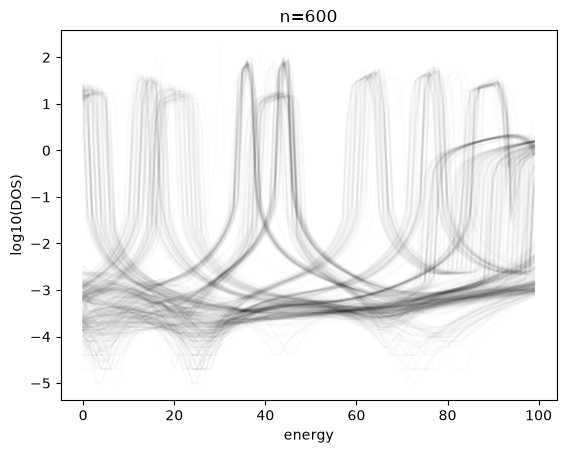

In [5]:
plot_x(g_df, g_descriptor_names)

In [6]:
# yの表示
from collections import Counter
g_target_elm_list = np.unique(g_df[g_target_name].values)
print(len(g_target_elm_list),g_target_elm_list)
counter = Counter(g_df[g_target_name].values)
counter

12 ['Bi' 'Hf' 'Hg' 'In' 'Mo' 'Nb' 'Pb' 'Sc' 'Sn' 'Tl' 'Y' 'Zr']


Counter({'Sn': 50,
         'Y': 50,
         'Tl': 50,
         'Sc': 50,
         'Pb': 50,
         'Bi': 50,
         'In': 50,
         'Zr': 50,
         'Hg': 50,
         'Hf': 50,
         'Nb': 50,
         'Mo': 50})

In [7]:
def smear_dos(v, newn, alpha, type_=1):
    """smear counter by 

    f(r), r_1,...r_M = sum_i^N exp(-alpha((r-i)^2))*v[i] if type_==1, i=1,N, M<N
    exp(-alpha((r-i)^2))*(r-i)^2 if type_==2,
    tanh(alpha((r-i)) if type_==3,
    
    この操作はNNの畳み込みとほぼ同じ操作です。

    Args:
        v (np.ndarray): values
        newn (int): new number of divisions
        alpha (float, optoinal): exp(-alpha*i*2). Defaults 1.0.

    Returns:
        np.ndarrays: smeared values
    """
    n = v.shape[1]

    i = [i for i in range(n)]
    i = np.array(i)/n
    
    r = np.linspace(0, 1, newn)

    r_i = r[np.newaxis, :]-i[:, np.newaxis]

    
    if type_ == 1:
        expr_r2 = np.exp(-alpha*r_i**2)
    elif type_ == 2:
        expr_r2 = np.exp(-alpha*r_i**2)*r_i**2
    elif type_ == 3:
        expr_r2 = np.tanh(alpha*r_i)
    else:
        raise ValueError("uknown type_={}".format(type_))

    expr_r2 = expr_r2[np.newaxis,:,:]
    
    v = v[:,:,np.newaxis]

    expr_r2_v = expr_r2 * v
    v2 = expr_r2_v.sum(axis=1)
    
    return v2, expr_r2


def add_convolution_variables(df, descriptor_names, n_new, alpha):
    """add convolution variables

    Args:
        df_obs (pd.DataFrame): データ。
        descriptor_names: 説明変数名リスト。
        n_new (int): 説明変数数。

    Returns：
        pd.DataFrame: データ
        [str]: descriptor_names: 
    """
    df = df.copy().reset_index(drop=True)
    X = df[descriptor_names].values

    v2, expr_r2 = smear_dos(df[descriptor_names].values, n_new, alpha=alpha)
    

    plt.plot(expr_r2[0,:,:])
    plt.title("expr_r2")
    
    smeared_names = []
    for i in range(n_new):
        smeared_names.append("smeared_dos{}".format(i))
        
    df_smeared = pd.DataFrame(v2, columns=smeared_names)
    return pd.concat([df,df_smeared], axis=1), smeared_names

In [8]:
from sklearn.decomposition import PCA
from sklearn.manifold import MDS, TSNE

def dr_transform(df_sample, descriptor_names, dr_type="tsne", 
                  dr_prefix = "dr", ndim = 2,  random_state=1):
    """dimensionality reductionを行う。
    
    Args:
        df_sample (pd.DataFrame): データ.
        descriptor_names ([str]): df_sampleの説明変数名リスト.
        DR_TYPE (str): dimensionality reductionの名前。
        df_prefix (str, optional): dimensionality reductionしたカラム名のprefix. Defaults to "dr"
        ndim (int, optional):  dimensionality reductionの次元。Defaults to 2.
        seed (int, optional): random seed. Defaults to 2.
    
    Returns:
        pd.DataFrame: データ.
        [str]: dimensionality reductionしたカラム名リスト。
    """
    df_sample = df_sample.copy()
    X = df_sample[descriptor_names].astype(float).values
    print("apply",dr_type,"ndim=",ndim)
    if dr_type=="pca":
        dr = PCA(ndim)
    elif dr_type=="mds":
        dr = MDS(ndim, random_state= random_state)
    elif dr_type=="tsne":
        dr = TSNE(ndim,  init="pca", random_state=random_state)
    else:
        raise ValueError("unknown rd_type={}".format(dr_type))
        
    dr_names = []
    for i in range(ndim):
        dr_names.append("{}{}".format(dr_prefix, i))
        
    Xdr = dr.fit_transform(X)
    df_dr = pd.DataFrame(Xdr, columns=dr_names)
    df_sample = pd.concat([df_sample, df_dr],axis=1)
            
    return df_sample, dr_names

In [9]:
if DR_TYPE is None:
    g_smearedlogdos_names = g_logdos_names
    g_descriptor_names = g_smearedlogdos_names
elif DR_TYPE=="smearing":
    g_df, g_smearedlogdos_names = add_convolution_variables(
        g_df, g_logdos_names, N_SMEARD_DOS, _SMEAR_ALPHA)
    #sns.pairplot(g_df[g_descriptor_names])
    g_descriptor_names = g_smearedlogdos_names
elif DR_TYPE == "pca" or DR_TYPE=="mds":
    g_df, g_smearedlogdos_names = dr_transform(
        g_df, g_logdos_names, dr_prefix=DR_TYPE, dr_type= DR_TYPE, ndim=N_SMEARD_DOS)
    g_descriptor_names = g_smearedlogdos_names
elif DR_TYPE == "tsne":
    if N_SMEARD_DOS<=5:
        g_df, g_smearedlogdos_names = dr_transform(
            g_df, g_logdos_names, dr_prefix=DR_TYPE, dr_type= DR_TYPE, ndim=N_SMEARD_DOS)
        g_descriptor_names = g_smearedlogdos_names   
    else:
        raise ValueError("It takes much time. DR_TYPE={} isn't supported.".format(DR_TYPE))
else:
    raise ValueError("unknown DR_TYPE={}".format(DR_TYPE))

In [10]:
# 図示するための二次元座標の用意。
# g_df[g_dr2_names]は二次元図示のためだけに用いる。
g_df, g_dr2_names = dr_transform(g_df, g_smearedlogdos_names,
                                        dr_type=DSP_DR_TYPE, dr_prefix = "dr2")

apply tsne ndim= 2


In [11]:
from sklearn.cluster import KMeans
from  sklearn.mixture import GaussianMixture

def df_clustering(df, descriptor_names, n_clusters, cluster_name="kmeans", random_state=1):
    """クラスリングをして結果を表示する。
    
    KMeans(n_clusters, n_init='auto',...) n_init is added to avoid printing a FutureWarning message.
    
    Args:
        df (pd.DataFrame): データ。
        descriptor_names ([str]): 説明変数名リスト。
        n_clusters (int): クラスタ数。
        
    Returns:
        pd.DataFrame: データ。
    """
    df = df.copy()
    kmeans = KMeans(n_clusters, n_init='auto', random_state=random_state)
    X = df[descriptor_names].values
    kmeans.fit(X)
    yp = kmeans.predict(X)
    df[cluster_name] = yp
    return df, cluster_name

def df_classification(df, descriptor_names, target_name, predicted_target_name="predict", random_state=1):
    """クラスリングをして結果を表示する。
    
    KMeans(n_clusters, n_init='auto',...) n_init is added to avoid printing a FutureWarning message.
    
    Args:
        df (pd.DataFrame): データ。
        descriptor_names ([str]): 説明変数名リスト。
        n_clusters (int): クラスタ数。
        
    Returns:
        pd.DataFrame: データ。
    """
    from sklearn.linear_model import LogisticRegression 
    df = df.copy()
    model = LogisticRegression()
    X = df[descriptor_names].values
    y = df[target_name].values
    model.fit(X,y)
    yp = model.predict(X)
    df[predicted_target_name] = yp
    return df, predicted_target_name

In [12]:
g_n_clusters=len(g_target_elm_list)
if not SECOND_PREPROCESS :
    g_df, g_predictedtarget_name = df_classification(g_df, g_descriptor_names, g_target_name)
else:
    g_df, g_predictedtarget_name = df_classification(g_df, g_dr2_names, g_target_name) # smearingしてからt-sneする。

/home/kino/miniforge3/envs/pymc_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


save to image_executed/cluster_None_50_5000_False_tsne.png


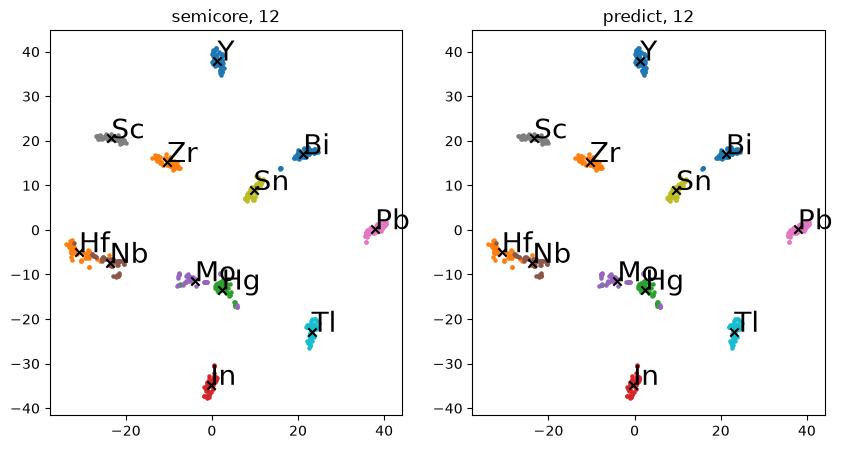

In [13]:
def plot_cluster(df, target_name, dr_names, ax,
                  alpha=1.0, s=5,         ):
    """クラスリングをした結果を表示する。

    Args:
        df (pd.DataFrame): data
        target_name (str): target variable name.
        dr_names ([str]]): a list of exaplanatory variables.
        ax (Axes): matplotlib axis.
        alpha (float, optional): alpha value of plot. Defaults to 1.0.
        s (int, optional): point size. Defaults to 5.
    """
    yp = df[target_name]
    X_dr = df[dr_names].values
    uniq_yp = np.unique(yp)
    n_clusters = uniq_yp.shape[0]
    
    for i in uniq_yp:
        idx = yp==i
        ax.scatter(X_dr[idx,0], X_dr[idx,1], alpha=alpha, s=s, label=str(i))  # ラベルを追加
        center = (X_dr[idx,0].mean(), X_dr[idx,1].mean())
        ax.text(center[0], center[1], str(i), fontsize=20)
        ax.scatter([center[0]], [center[1]], marker="x", color="black")
    ax.set_title("{}, {}".format(target_name, n_clusters))
    # ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0,)
    

def plot_clusters(df, target_names,  dr2_names,  alpha=1.0, s=5):
    """クラスタを可視化表示する。

    Args:
        df (pd.DataFrame): data
        target_names ([str]): a list of target names.
        dr2_names ([str]): explanatory variables.
        alpha (float, optional): alpha channel value of ploot. Defaults to 1.0.
        s (int, optional): point size. Defaults to 5.
    """
    fig, axes = plt.subplots(1,len(target_names),figsize=(10,5))
    for name,ax in zip(target_names, axes):
        plot_cluster(df, name, dr2_names, ax, alpha, s)
    figfilename =  "cluster_{}.png".format("_".join([DR_TYPE if DR_TYPE is not None else "None",
                                str(N_SMEARD_DOS),
                               str(_SMEAR_ALPHA),str(SECOND_PREPROCESS),
                               DSP_DR_TYPE]))
    figpath = os.path.join(FIGDIR,figfilename)
    fig.savefig(figpath)
    print("save to", figpath)
        
plot_clusters(g_df, [g_target_name,g_predictedtarget_name],  g_dr2_names)

In [14]:
from sklearn.metrics import classification_report
msg = classification_report(g_df[g_target_name],g_df[g_predictedtarget_name]) # 文字列を返す。
print(msg)

              precision    recall  f1-score   support

          Bi       1.00      1.00      1.00        50
          Hf       1.00      1.00      1.00        50
          Hg       1.00      0.98      0.99        50
          In       1.00      1.00      1.00        50
          Mo       0.98      1.00      0.99        50
          Nb       1.00      1.00      1.00        50
          Pb       1.00      1.00      1.00        50
          Sc       1.00      1.00      1.00        50
          Sn       1.00      1.00      1.00        50
          Tl       1.00      1.00      1.00        50
           Y       1.00      1.00      1.00        50
          Zr       1.00      1.00      1.00        50

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



上図のMo, Hgの分離が最も問題になります。

smearnigしてから二次元tsneを行った変数が最も分離度が良さそうです。
このscriptではSECOND_PREPROCESS=Trueとするとsmearnigしてから二次元tsne後の変数のクラスタリングを行います。

In [15]:
from sklearn.metrics import confusion_matrix
def make_cm_save(df, target_name, predictedtarget_name, target_elm_list, dr_type, n_dr_dim):
    """
    confusion matrixを作りセーブする。
    
    Args:
        df (pd.DataFrame): データ。
        target_name (str): 観測値目的変数名カラム。
        predictedtarget_name (str): 予測値目的変数名カラム。
        target_elm_list ([str]): 観測値のユニークリスト。
        dr_type (str): 次元圧縮手法名。
        n_dr_dim (int): 次元圧縮後の次元。
        
    Returns:
        csvファイル名。
    """

    cm = confusion_matrix(df[target_name],df[predictedtarget_name])
    # 上のcluster番号と名前の対応がつかなかった場合はエラーが起きる。
    
    df_cm = pd.DataFrame(cm, index=target_elm_list,columns=target_elm_list)
    display(df_cm)
    
    OUTPUTDIR="data_executed"
    os.makedirs(OUTPUTDIR, exist_ok=True)
    filename = "hea4_y_yp_{}_{}.csv".format(dr_type, n_dr_dim)
    filepath = os.path.join(OUTPUTDIR,
                              filename)
    df[[target_name,predictedtarget_name]].to_csv(filepath, index=False)
    print("saved to",filepath)
    return filepath

if not SECOND_PREPROCESS:

    if DR_TYPE is None:
        g_filepath = make_cm_save(g_df, g_target_name, g_predictedtarget_name, g_target_elm_list, 
                                  DR_TYPE, len(g_logdos_names))
    else:
        g_filepath = make_cm_save(g_df, g_target_name, g_predictedtarget_name, g_target_elm_list, 
                                  DR_TYPE, N_SMEARD_DOS)
else:
    g_filepath = make_cm_save(g_df, g_target_name, g_predictedtarget_name, g_target_elm_list, 
                                  "smearing-{}-2".format(DSP_DR_TYPE), N_SMEARD_DOS)

,Bi,Hf,Hg,In,Mo,Nb,Pb,Sc,Sn,Tl,Y,Zr
Bi,50,0,0,0,0,0,0,0,0,0,0,0
Hf,0,50,0,0,0,0,0,0,0,0,0,0
Hg,0,0,49,0,1,0,0,0,0,0,0,0
In,0,0,0,50,0,0,0,0,0,0,0,0
Mo,0,0,0,0,50,0,0,0,0,0,0,0
Nb,0,0,0,0,0,50,0,0,0,0,0,0
Pb,0,0,0,0,0,0,50,0,0,0,0,0
Sc,0,0,0,0,0,0,0,50,0,0,0,0
Sn,0,0,0,0,0,0,0,0,50,0,0,0
Tl,0,0,0,0,0,0,0,0,0,50,0,0


saved to data_executed/hea4_y_yp_None_100.csv


In [16]:
pd.read_csv(g_filepath)

,semicore,predict
0,Sn,Sn
1,Sn,Sn
2,Sn,Sn
3,Sn,Sn
4,Sn,Sn
...,...,...
595,Mo,Mo
596,Mo,Mo
597,Mo,Mo
598,Mo,Mo


In [17]:
DR_TYPE, N_SMEARD_DOS,"done"

(None, 50, 'done')